In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols, logit
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.multicomp import pairwise_tukeyhsd




In [2]:
df = pd.read_csv("./test.csv")

df.head()
df = df.iloc[:, 1:]

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   line           300 non-null    object 
 1   work_shift     300 non-null    object 
 2   supplier       300 non-null    object 
 3   oven_temp      300 non-null    float64
 4   humidity       300 non-null    float64
 5   speed          300 non-null    float64
 6   thickness      300 non-null    float64
 7   defect         300 non-null    int64  
 8   rework_min     300 non-null    float64
 9   thickness_dev  300 non-null    float64
dtypes: float64(6), int64(1), object(3)
memory usage: 23.6+ KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
oven_temp,300.0,229.559333,5.091650,215.20,225.9750,229.40,232.800,243.00
humidity,300.0,50.042333,7.967516,20.80,45.4000,50.35,55.025,75.40
speed,300.0,1.194967,0.152928,0.78,1.0975,1.20,1.300,1.62
thickness,300.0,106.435000,9.613776,83.20,99.7750,106.60,112.925,131.30
defect,300.0,0.136667,0.344069,0.00,0.0000,0.00,0.000,1.00
rework_min,300.0,28.733333,21.953154,4.60,16.4000,23.40,34.025,173.70
thickness_dev,300.0,8.214333,6.121722,0.10,3.2750,6.90,12.600,26.80


In [5]:
ALPHA = 0.05
LOG = []

def verdict (name , p , h0 , reject_msg = "", keep_msg = "", stat = None, alpha = ALPHA):
    rejected = p < alpha
    sign = "<" if rejected else ">="
    print(f"--------------[{name}]=========")
    print(f"     H0 : {h0}     ")
    if stat is not None :
        print(f"검정통계량 = {stat : .4f}")

    print(f"p-value = {p:.6f}   {sign}    alpha = {alpha}")
    if rejected :
        print(f"귀무가설 기가 : {reject_msg}")

    else :
        print(f" 귀무가설 기각 못한 : {keep_msg}")
    LOG.append({"검정":name , "p-value": p , "판결" : "기각" if rejected else " 기각못함"})

verdict("테스트", p = 0.03, h0= "차이없다", reject_msg= "차이가 있다",keep_msg= "차이가 없다고 단정 못함")

LOG.clear()

--------------[테스트]=========
     H0 : 차이없다     
p-value = 0.030000   <    alpha = 0.05
귀무가설 기가 : 차이가 있다


alpha = 0.01 --> 잘못 기각한 비율(1종 오류률) = 0.012
alpha = 0.05 --> 잘못 기각한 비율(1종 오류률) = 0.055
alpha = 0.01 --> 잘못 기각한 비율(1종 오류률) = 0.012


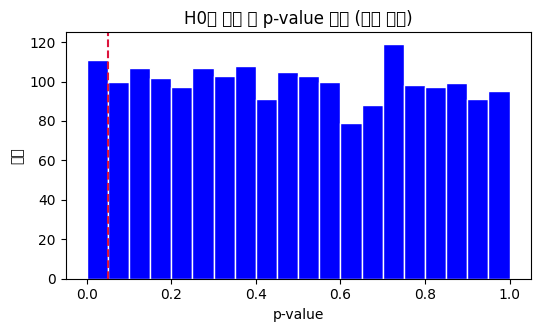

In [ ]:
sim = np.random.default_rng(0)
TRIALS = 2000

def simulate_pvalues(true_diff, n, sd = 8):
    a = sim.normal(110 , sd , (TRIALS , n))
    b = sim.normal(110 + true_diff , sd, (TRIALS, n))
    return stats . ttest_ind(a,b,axis = 1).pvalue

p_h0 = simulate_pvalues(0,30)

for a in [0.01 , 0.05 , 0.01]:
    print(f"alpha = {a:<4} --> 잘못 기각한 비율(1종 오류률) = {(p_h0 <a).mean():.3f}")

plt.figure(figsize = (6,3.2))
plt.hist(p_h0, bins=20 , color= "blue", edgecolor = "white")
plt.axvline(0.05, color = "crimson", ls = "--", label = "alpha = 0.05")
plt.title("H0가 참일 때 p-value 분포 (거의 평평)")
plt.xlabel("p-value")
plt.ylabel("횟수")
plt.show()
plt.show()

 표준크기 n  검정력(1-B)  2종오류(b):
      5    0.1020    0.8980
     10    0.1860    0.8140
     20    0.3765    0.6235
     30    0.4870    0.5130
     50    0.6955    0.3045
    100    0.9390    0.0610


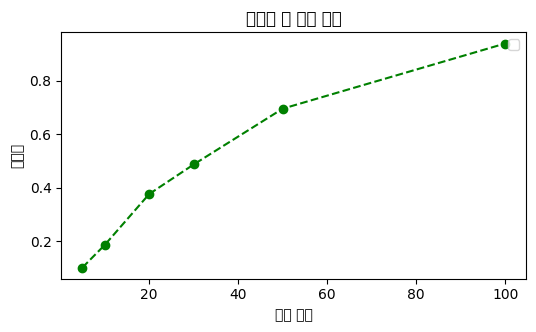

In [ ]:
rows= []

for n in [5,10,20,30,50,100]:
    p = simulate_pvalues(true_diff=4, n=n)
    power = (p<0.05).mean()
    rows.append({"표준크기 n" : n , "검정력(1-B)" : power , "2종오류(b):" : 1 - power})

power_df = pd.DataFrame(rows)
print(power_df.to_string(index = False))

plt.figure(figsize = (6,3.2))
plt.plot(power_df["표준크기 n"], power_df["검정력(1-B)"], "o--", color="green")
plt.title("표본이 클 수록 좋다")
plt.xlabel("표본 크기")
plt.ylabel("검정력")
plt.legend()
plt.show()

In [14]:
p = simulate_pvalues(true_diff= 4, n =30)
for a in [0.10, 0.05, 0.01]:
    print ( f"alpha = {a : <4}--> 1종오류 확률 = {a:<4} | 검정력 = {(p<a).mean():3f} | 2종오류베타  = { ( p>=a).mean():.3f}")

alpha = 0.1 --> 1종오류 확률 = 0.1  | 검정력 = 0.605000 | 2종오류베타  = 0.395
alpha = 0.05--> 1종오류 확률 = 0.05 | 검정력 = 0.477000 | 2종오류베타  = 0.523
alpha = 0.01--> 1종오류 확률 = 0.01 | 검정력 = 0.251000 | 2종오류베타  = 0.749


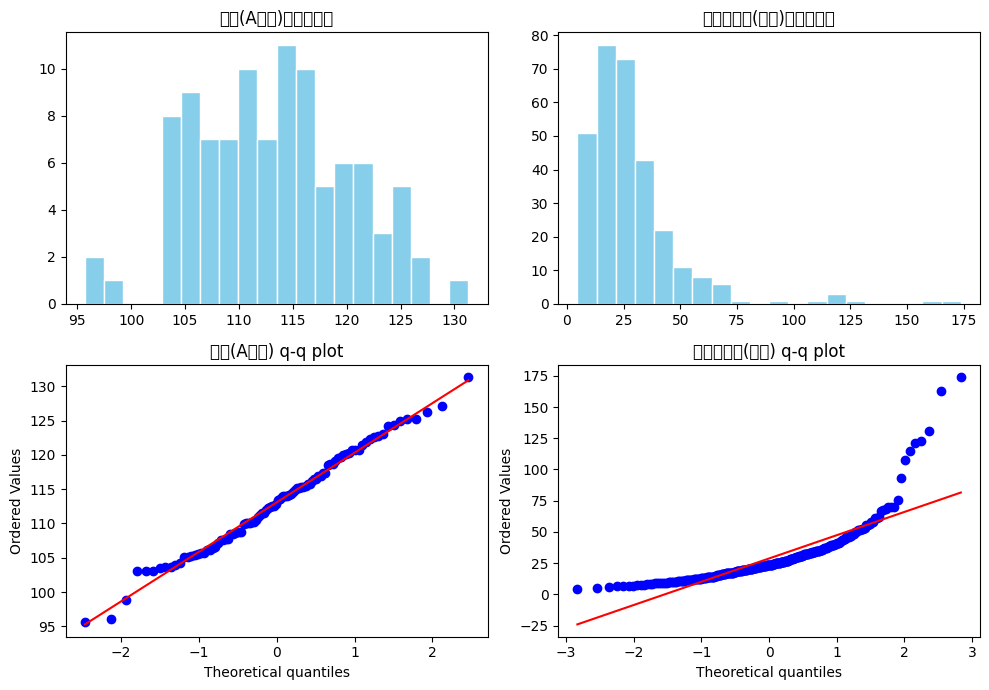

In [17]:
fig, ax = plt.subplots(2, 2, figsize = (10,7))

for col , (var, title) in enumerate([("thickness", "두께(A라인)"),("rework_min","재작업시간(전체)")]):
    x = df.loc[df.line == "A", var]if var == "thickness" else df[var]
    ax[0, col].hist(x , bins = 20 , color = "skyblue", edgecolor = "white")
    ax[0, col].set_title(f'{title}히스토그램')
    stats.probplot(x, dist = "norm", plot= ax[1 ,col])
    ax [1, col].set_title(f"{title} q-q plot")

plt.tight_layout()
plt.show()

In [21]:
l_data = np.array([119,110,108,120,117,109,96,104,123,113,129,106,93,92,102])

print(stats.shapiro(l_data))

for name, x in [("A라인 두께",df.loc[df.line == "A","thickness"]),
                ("B라인 두께",df.loc[df.line == "B", "thickness"]),
                ("C라인 두께",df.loc[df.line == "C", "thickness"]),
                ("재작업 시간", df["rework_min"])
                ]:
    res = stats.shapiro(x)
    verdict(f"정규성 : {name}",res.pvalue, "데이터는 정규분포를따른다",
            reject_msg = "정규분포가 아니다", keep_msg = '정규분포라고 볼 수 있다.',
            stat= res.statistic)

    

ShapiroResult(statistic=0.9740516543388367, pvalue=0.9128594994544983)
--------------[정규성 : A라인 두께]=========
     H0 : 데이터는 정규분포를따른다     
검정통계량 =  0.9907
p-value = 0.719597   >=    alpha = 0.05
 귀무가설 기각 못한 : 정규분포라고 볼 수 있다.
--------------[정규성 : B라인 두께]=========
     H0 : 데이터는 정규분포를따른다     
검정통계량 =  0.9891
p-value = 0.594496   >=    alpha = 0.05
 귀무가설 기각 못한 : 정규분포라고 볼 수 있다.
--------------[정규성 : C라인 두께]=========
     H0 : 데이터는 정규분포를따른다     
검정통계량 =  0.9850
p-value = 0.319109   >=    alpha = 0.05
 귀무가설 기각 못한 : 정규분포라고 볼 수 있다.
--------------[정규성 : 재작업 시간]=========
     H0 : 데이터는 정규분포를따른다     
검정통계량 =  0.7161
p-value = 0.000000   <    alpha = 0.05
귀무가설 기가 : 정규분포가 아니다
